In [2]:
import pandas as pd

train = pd.read_csv("../data/raw/train.csv")
store = pd.read_csv("../data/raw/store.csv")

print(train.shape)
print(store.shape)
train.head()

(1017209, 9)
(1115, 10)


C:\Users\SP\AppData\Local\Temp\ipykernel_25236\3868093654.py:3: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("../data/raw/train.csv")


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 79.5+ MB


In [4]:
train.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [5]:
train['Date'] = pd.to_datetime(train['Date'])
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[us]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  object        
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[us](1), int64(7), object(1)
memory usage: 69.8+ MB


In [6]:
store.info()
store.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   str    
 2   Assortment                 1115 non-null   str    
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    str    
dtypes: float64(5), int64(2), str(3)
memory usage: 98.0 KB


Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

In [7]:
store.groupby('Promo2')['Promo2SinceWeek'].apply(lambda x: x.isnull().sum())

Promo2
0    544
1      0
Name: Promo2SinceWeek, dtype: int64

In [8]:
df = train.merge(store, on='Store', how='left')
print(df.shape)
df.head()

(1017209, 18)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [9]:
print(df.shape[0] == train.shape[0])

True


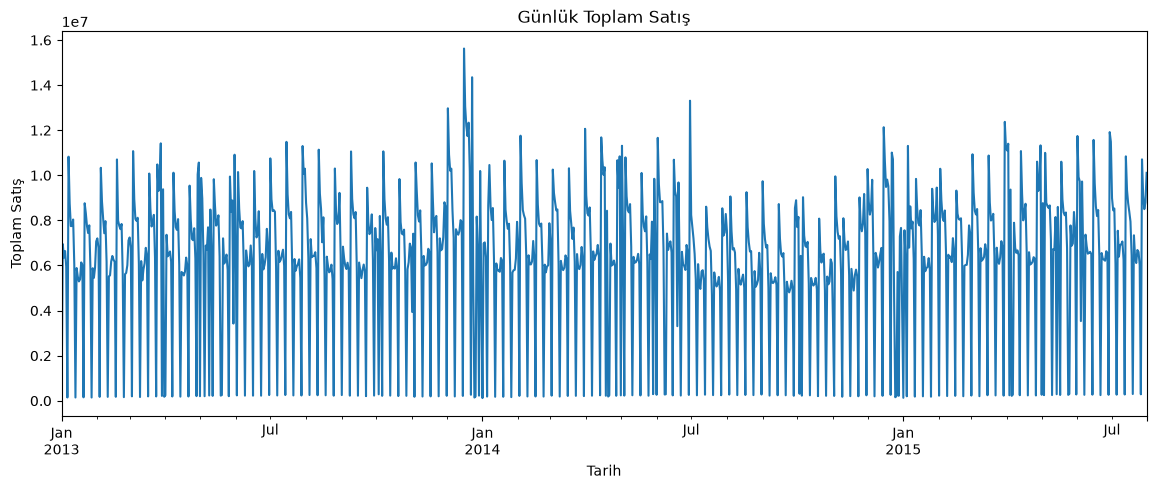

In [10]:
daily_sales = df.groupby('Date')['Sales'].sum()

import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))
daily_sales.plot()
plt.title('Günlük Toplam Satış')
plt.xlabel('Tarih')
plt.ylabel('Toplam Satış')
plt.show()

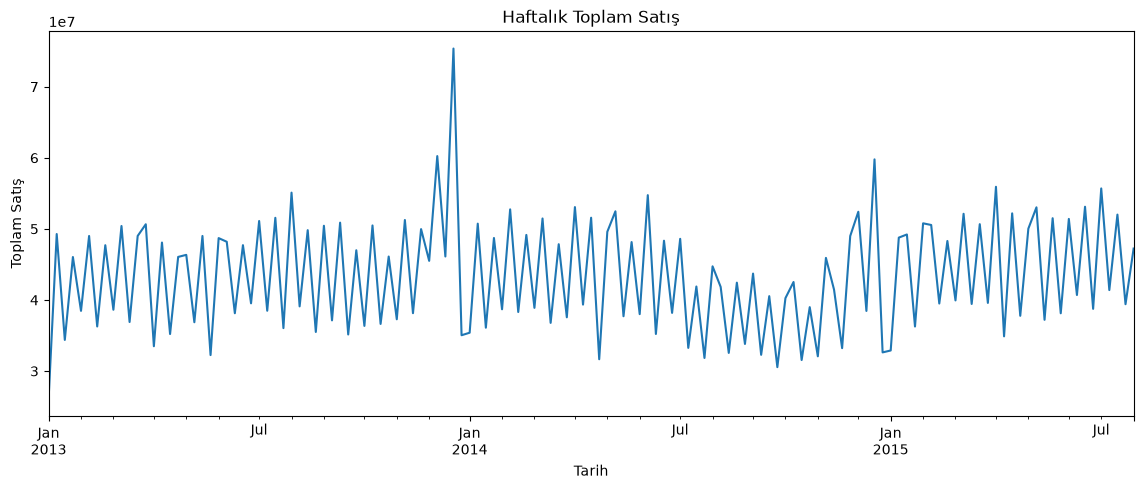

In [11]:
weekly_sales = daily_sales.resample('W').sum()

plt.figure(figsize=(14,5))
weekly_sales.plot()
plt.title('Haftalık Toplam Satış')
plt.xlabel('Tarih')
plt.ylabel('Toplam Satış')
plt.show()

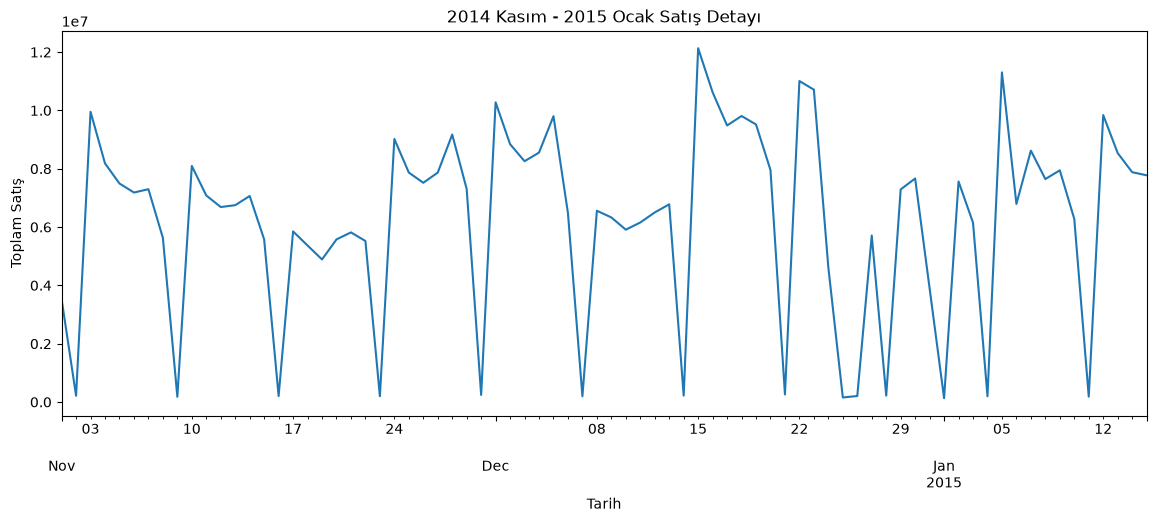

In [12]:
zoom = daily_sales['2014-11-01':'2015-01-15']

plt.figure(figsize=(14,5))
zoom.plot()
plt.title('2014 Kasım - 2015 Ocak Satış Detayı')
plt.xlabel('Tarih')
plt.ylabel('Toplam Satış')
plt.show()

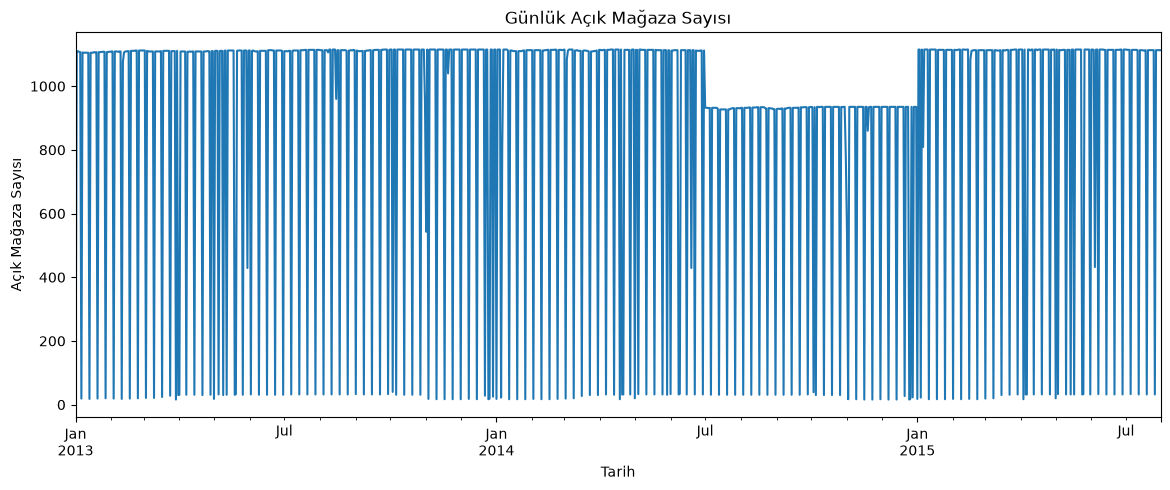

In [13]:
open_stores = df.groupby('Date')['Open'].sum()

plt.figure(figsize=(14,5))
open_stores.plot()
plt.title('Günlük Açık Mağaza Sayısı')
plt.xlabel('Tarih')
plt.ylabel('Açık Mağaza Sayısı')
plt.show()

In [14]:
df.groupby('DayOfWeek')['Sales'].mean()

DayOfWeek
1    7809.044510
2    7005.244467
3    6555.884138
4    6247.575913
5    6723.274305
6    5847.562599
7     204.183189
Name: Sales, dtype: float64

In [15]:
df_open = df[df['Open'] == 1].copy()
print(df_open.shape)

(844392, 18)


In [16]:
df_open.groupby('Promo')['Sales'].mean()

Promo
0    5929.407603
1    8228.281239
Name: Sales, dtype: float64

In [17]:
df_open.groupby('StateHoliday')['Sales'].mean()

StateHoliday
0    6701.492117
0    6992.158856
a    8487.471182
b    9887.889655
c    9743.746479
Name: Sales, dtype: float64

In [18]:
df_open.groupby('StoreType')['Sales'].mean()

StoreType
a     6925.167661
b    10231.407505
c     6932.512755
d     6822.141881
Name: Sales, dtype: float64

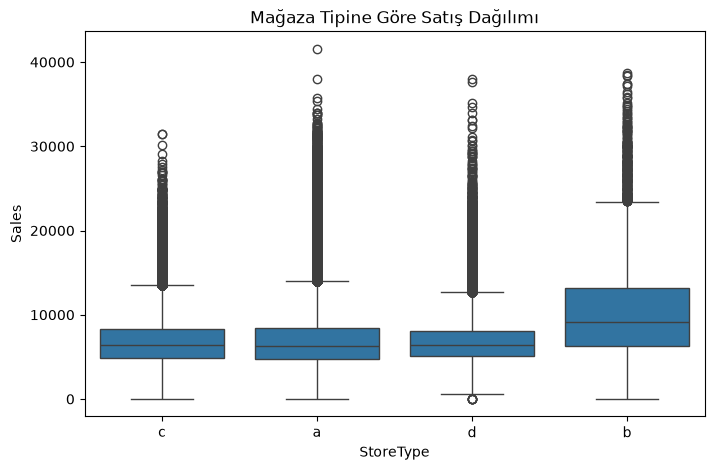

In [19]:
import seaborn as sns

plt.figure(figsize=(8,5))
sns.boxplot(data=df_open, x='StoreType', y='Sales')
plt.title('Mağaza Tipine Göre Satış Dağılımı')
plt.show()

In [20]:
df_open['StateHoliday'].unique()
df_open['StateHoliday'].apply(type).value_counts()

StateHoliday
<class 'str'>    732252
<class 'int'>    112140
Name: count, dtype: int64

In [21]:
df_open['StateHoliday'] = df_open['StateHoliday'].astype(str)
df_open['StateHoliday'].unique()

<ArrowStringArray>
['0', 'a', 'b', 'c']
Length: 4, dtype: str

In [22]:
df_open.groupby('StateHoliday')['Sales'].mean()

StateHoliday
0    6953.515034
a    8487.471182
b    9887.889655
c    9743.746479
Name: Sales, dtype: float64

In [23]:
df_open['Year'] = df_open['Date'].dt.year
df_open['Month'] = df_open['Date'].dt.month
df_open['Day'] = df_open['Date'].dt.day
df_open['WeekOfYear'] = df_open['Date'].dt.isocalendar().week
df_open['Quarter'] = df_open['Date'].dt.quarter

df_open[['Date', 'Year', 'Month', 'Day', 'WeekOfYear', 'Quarter']].head()

,Date,Year,Month,Day,WeekOfYear,Quarter
0,2015-07-31,2015,7,31,31,3
1,2015-07-31,2015,7,31,31,3
2,2015-07-31,2015,7,31,31,3
3,2015-07-31,2015,7,31,31,3
4,2015-07-31,2015,7,31,31,3


In [24]:
df_open = df_open.sort_values(['Store', 'Date']).reset_index(drop=True)

In [25]:
for lag in [7, 14, 28]:
    df_open[f'Sales_lag_{lag}'] = df_open.groupby('Store')['Sales'].shift(lag)

df_open[['Store', 'Date', 'Sales', 'Sales_lag_7', 'Sales_lag_14', 'Sales_lag_28']].head(10)

,Store,Date,Sales,Sales_lag_7,Sales_lag_14,Sales_lag_28
0,1,2013-01-02,5530,NaN,NaN,NaN
1,1,2013-01-03,4327,NaN,NaN,NaN
2,1,2013-01-04,4486,NaN,NaN,NaN
3,1,2013-01-05,4997,NaN,NaN,NaN
4,1,2013-01-07,7176,NaN,NaN,NaN
5,1,2013-01-08,5580,NaN,NaN,NaN
6,1,2013-01-09,5471,NaN,NaN,NaN
7,1,2013-01-10,4892,5530.0,NaN,NaN
8,1,2013-01-11,4881,4327.0,NaN,NaN
9,1,2013-01-12,4952,4486.0,NaN,NaN


In [26]:
df = df.sort_values(['Store', 'Date']).reset_index(drop=True)

df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['WeekOfYear'] = df['Date'].dt.isocalendar().week
df['Quarter'] = df['Date'].dt.quarter

for lag in [7, 14, 28]:
    df[f'Sales_lag_{lag}'] = df.groupby('Store')['Sales'].shift(lag)

df[['Store', 'Date', 'Open', 'Sales', 'Sales_lag_7', 'Sales_lag_14', 'Sales_lag_28']].head(15)

,Store,Date,Open,Sales,Sales_lag_7,Sales_lag_14,Sales_lag_28
0,1,2013-01-01,0,0,NaN,NaN,NaN
1,1,2013-01-02,1,5530,NaN,NaN,NaN
2,1,2013-01-03,1,4327,NaN,NaN,NaN
3,1,2013-01-04,1,4486,NaN,NaN,NaN
4,1,2013-01-05,1,4997,NaN,NaN,NaN
5,1,2013-01-06,0,0,NaN,NaN,NaN
6,1,2013-01-07,1,7176,NaN,NaN,NaN
7,1,2013-01-08,1,5580,0.0,NaN,NaN
8,1,2013-01-09,1,5471,5530.0,NaN,NaN
9,1,2013-01-10,1,4892,4327.0,NaN,NaN


In [27]:
df['check_gap'] = df.groupby('Store')['Date'].diff(7).dt.days
df['check_gap'].value_counts()

check_gap
7.0      1008144
191.0       1260
Name: count, dtype: int64

In [28]:
import numpy as np

for lag in [7, 14, 28]:
    gap = df.groupby('Store')['Date'].diff(lag).dt.days
    df.loc[gap != lag, f'Sales_lag_{lag}'] = np.nan

# Kontrol
for lag in [7, 14, 28]:
    print(f'Sales_lag_{lag} eksik sayısı:', df[f'Sales_lag_{lag}'].isnull().sum())

Sales_lag_7 eksik sayısı: 9065
Sales_lag_14 eksik sayısı: 18130
Sales_lag_28 eksik sayısı: 36260


In [29]:
for window in [7, 14, 30]:
    df[f'Sales_rolling_mean_{window}'] = (
        df.groupby('Store')['Sales']
          .shift(1)
          .rolling(window)
          .mean()
          .reset_index(drop=True)
    )
    df[f'Sales_rolling_std_{window}'] = (
        df.groupby('Store')['Sales']
          .shift(1)
          .rolling(window)
          .std()
          .reset_index(drop=True)
    )

df[['Store', 'Date', 'Sales', 'Sales_rolling_mean_7', 'Sales_rolling_std_7']].head(15)

,Store,Date,Sales,Sales_rolling_mean_7,Sales_rolling_std_7
0,1,2013-01-01,0,NaN,NaN
1,1,2013-01-02,5530,NaN,NaN
2,1,2013-01-03,4327,NaN,NaN
3,1,2013-01-04,4486,NaN,NaN
4,1,2013-01-05,4997,NaN,NaN
5,1,2013-01-06,0,NaN,NaN
6,1,2013-01-07,7176,NaN,NaN
7,1,2013-01-08,5580,3788.000000,2752.283961
8,1,2013-01-09,5471,4585.142857,2231.018633
9,1,2013-01-10,4892,4576.714286,2226.961885


In [30]:
for window in [7, 14, 30]:
    gap = df.groupby('Store')['Date'].diff(window).dt.days
    df.loc[gap != window, f'Sales_rolling_mean_{window}'] = np.nan
    df.loc[gap != window, f'Sales_rolling_std_{window}'] = np.nan

for window in [7, 14, 30]:
    print(f'Sales_rolling_mean_{window} eksik sayısı:', df[f'Sales_rolling_mean_{window}'].isnull().sum())

Sales_rolling_mean_7 eksik sayısı: 9065
Sales_rolling_mean_14 eksik sayısı: 18130
Sales_rolling_mean_30 eksik sayısı: 38850


In [31]:
# Hafta sonu flag'i (DayOfWeek 6=Cumartesi, 7=Pazar)
df['IsWeekend'] = df['DayOfWeek'].isin([6, 7]).astype(int)

# Yılbaşına kaç gün kaldığı (EDA'da bulduğumuz Kasım-Aralık artışını doğrudan yakalar)
df['Christmas_this_year'] = pd.to_datetime(df['Year'].astype(str) + '-12-25')
df['DaysToChristmas'] = (df['Christmas_this_year'] - df['Date']).dt.days

mask = df['DaysToChristmas'] < 0
df.loc[mask, 'Christmas_this_year'] = pd.to_datetime((df.loc[mask, 'Year'] + 1).astype(str) + '-12-25')
df.loc[mask, 'DaysToChristmas'] = (df.loc[mask, 'Christmas_this_year'] - df.loc[mask, 'Date']).dt.days

df = df.drop(columns='Christmas_this_year')

# Rakip mağaza bu tarihte gerçekten açık mı
df['CompetitionOpen'] = (
    (df['Year'] > df['CompetitionOpenSinceYear']) |
    ((df['Year'] == df['CompetitionOpenSinceYear']) & (df['Month'] >= df['CompetitionOpenSinceMonth']))
).astype(int)
df.loc[df['CompetitionOpenSinceYear'].isnull(), 'CompetitionOpen'] = 0

df[['Date', 'DayOfWeek', 'IsWeekend', 'DaysToChristmas', 'CompetitionOpenSinceYear', 'CompetitionOpenSinceMonth', 'CompetitionOpen']].sample(10)

,Date,DayOfWeek,IsWeekend,DaysToChristmas,CompetitionOpenSinceYear,CompetitionOpenSinceMonth,CompetitionOpen
621671,2013-07-23,2,0,155,2014.0,7.0,0
155045,2015-03-05,4,0,295,NaN,NaN,0
468341,2013-07-03,3,0,175,2012.0,7.0,1
667643,2015-07-05,7,1,173,1999.0,10.0,1
708866,2013-10-06,7,1,80,2004.0,4.0,1
442387,2013-09-17,2,0,99,NaN,NaN,0
307599,2014-09-26,5,0,90,NaN,NaN,0
46812,2013-08-31,6,1,116,2014.0,4.0,0
800841,2013-03-19,2,0,281,NaN,NaN,0
252080,2013-06-12,3,0,196,2010.0,2.0,1


In [32]:
from sklearn.preprocessing import LabelEncoder

cat_cols = ['StoreType', 'Assortment', 'StateHoliday']

encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col + '_enc'] = le.fit_transform(df[col].astype(str))
    encoders[col] = le

df[['StoreType', 'StoreType_enc', 'Assortment', 'Assortment_enc', 'StateHoliday', 'StateHoliday_enc']].drop_duplicates().sort_values('StoreType')

,StoreType,StoreType_enc,Assortment,Assortment_enc,StateHoliday,StateHoliday_enc
942,a,0,a,0,a,1
943,a,0,a,0,0,0
1029,a,0,a,0,b,2
1300,a,0,a,0,c,3
1325,a,0,a,0,0,0
5652,a,0,c,2,a,1
5653,a,0,c,2,0,0
5739,a,0,c,2,b,2
6010,a,0,c,2,c,3
6035,a,0,c,2,0,0


In [33]:
print(df['Date'].min(), '-', df['Date'].max())

2013-01-01 00:00:00 - 2015-07-31 00:00:00


In [34]:
split_date = '2015-06-19'

train_df = df[df['Date'] < split_date].copy()
test_df = df[df['Date'] >= split_date].copy()

print('Train:', train_df.shape, train_df['Date'].min(), '-', train_df['Date'].max())
print('Test:', test_df.shape, test_df['Date'].min(), '-', test_df['Date'].max())

Train: (969264, 39) 2013-01-01 00:00:00 - 2015-06-18 00:00:00
Test: (47945, 39) 2015-06-19 00:00:00 - 2015-07-31 00:00:00


In [35]:
train_df = train_df[train_df['Open'] == 1]

feature_check_cols = ['Sales_lag_7', 'Sales_lag_14', 'Sales_lag_28',
                       'Sales_rolling_mean_7', 'Sales_rolling_mean_14', 'Sales_rolling_mean_30']
train_df = train_df.dropna(subset=feature_check_cols)

print('Temizlenmiş Train:', train_df.shape)

Temizlenmiş Train: (770908, 39)


In [36]:
import numpy as np

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mape(y_true, y_pred):
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

In [37]:
test_eval = test_df[(test_df['Open'] == 1) & (test_df['Sales_lag_7'].notnull())].copy()

baseline_rmse = rmse(test_eval['Sales'].values, test_eval['Sales_lag_7'].values)
baseline_mape = mape(test_eval['Sales'].values, test_eval['Sales_lag_7'].values)

print('Baseline RMSE:', round(baseline_rmse, 2))
print('Baseline MAPE:', round(baseline_mape, 2), '%')

Baseline RMSE: 2809.07
Baseline MAPE: 31.82 %


In [38]:
feature_cols = [
    'Store', 'DayOfWeek', 'Promo', 'SchoolHoliday', 'StateHoliday_enc',
    'StoreType_enc', 'Assortment_enc', 'CompetitionDistance', 'CompetitionOpen',
    'Promo2', 'Year', 'Month', 'Day', 'WeekOfYear', 'Quarter', 'IsWeekend', 'DaysToChristmas',
    'Sales_lag_7', 'Sales_lag_14', 'Sales_lag_28',
    'Sales_rolling_mean_7', 'Sales_rolling_std_7',
    'Sales_rolling_mean_14', 'Sales_rolling_std_14',
    'Sales_rolling_mean_30', 'Sales_rolling_std_30'
]

train_model_df = train_df.dropna(subset=feature_cols)

X_train = train_model_df[feature_cols]
y_train = train_model_df['Sales']

X_test = test_eval[feature_cols]
y_test = test_eval['Sales']

print(X_train.shape, X_test.shape)

(768932, 26) (41396, 26)


In [39]:
from xgboost import XGBRegressor

model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

model.fit(X_train, y_train)

preds = model.predict(X_test)

xgb_rmse = rmse(y_test.values, preds)
xgb_mape = mape(y_test.values, preds)

print('XGBoost RMSE:', round(xgb_rmse, 2))
print('XGBoost MAPE:', round(xgb_mape, 2), '%')
print()
print('Baseline RMSE:', round(baseline_rmse, 2))
print('Baseline MAPE:', round(baseline_mape, 2), '%')

XGBoost RMSE: 888.36
XGBoost MAPE: 9.12 %

Baseline RMSE: 2809.07
Baseline MAPE: 31.82 %


In [40]:
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
import numpy as np
import pandas as pd

# Test setindeki gerçek Sales değerleri
y_true = test_df['Sales'].values

# Naive tahmin: Sales_lag_7
y_pred_naive = test_df['Sales_lag_7'].values

# Geçerli satırları al (NaN olmayan)
valid = ~np.isnan(y_pred_naive)
rmse_naive = np.sqrt(mean_squared_error(y_true[valid], y_pred_naive[valid]))
mape_naive = mean_absolute_percentage_error(y_true[valid], y_pred_naive[valid])

print(f"Naive Baseline RMSE: {rmse_naive:.2f}")
print(f"Naive Baseline MAPE : {mape_naive:.4f}")

# Baseline sonuçlarını sakla
baseline_results = {'RMSE': rmse_naive, 'MAPE': mape_naive}
#deepseek ile yapıldı bu hücre ve bundan sonraki modeling hücreleri

Naive Baseline RMSE: 2614.59
Naive Baseline MAPE : 11403514409477642.0000


In [41]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=3)
cv_rmse_scores = []
cv_mape_scores = []

X_train_full = train_model_df[feature_cols].reset_index(drop=True)
y_train_full = train_model_df['Sales'].reset_index(drop=True)

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train_full)):
    X_tr, X_val = X_train_full.iloc[tr_idx], X_train_full.iloc[val_idx]
    y_tr, y_val = y_train_full.iloc[tr_idx], y_train_full.iloc[val_idx]

    cv_model = XGBRegressor(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        early_stopping_rounds=50,
        eval_metric='rmse'
    )
    # early stopping burada gerçek bir doğrulama setini (X_val, y_val) izliyor, train'i değil
    cv_model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)

    val_preds = cv_model.predict(X_val)
    fold_rmse = rmse(y_val.values, val_preds)
    fold_mape = mape(y_val.values, val_preds)
    cv_rmse_scores.append(fold_rmse)
    cv_mape_scores.append(fold_mape)
    print(f'Fold {fold+1} -> RMSE: {round(fold_rmse,2)}, MAPE: {round(fold_mape,2)}%')

print()
print(f'CV RMSE ortalaması: {round(np.mean(cv_rmse_scores),2)} (+/- {round(np.std(cv_rmse_scores),2)})')
print(f'CV MAPE ortalaması: {round(np.mean(cv_mape_scores),2)}% (+/- {round(np.std(cv_mape_scores),2)})')

Fold 1 -> RMSE: 856.7, MAPE: 8.8%
Fold 2 -> RMSE: 838.31, MAPE: 8.49%
Fold 3 -> RMSE: 774.66, MAPE: 8.32%

CV RMSE ortalaması: 823.22 (+/- 35.15)
CV MAPE ortalaması: 8.54% (+/- 0.2)


In [42]:
segment_results = []
all_segment_preds = np.zeros(len(y_test))
all_segment_true = y_test.values

for st in sorted(train_model_df['StoreType'].unique()):
    train_mask = train_model_df['StoreType'] == st
    test_mask = test_eval['StoreType'] == st

    if train_mask.sum() < 100 or test_mask.sum() < 10:
        continue

    X_tr_st = train_model_df.loc[train_mask, feature_cols]
    y_tr_st = train_model_df.loc[train_mask, 'Sales']
    X_te_st = test_eval.loc[test_mask, feature_cols]
    y_te_st = test_eval.loc[test_mask, 'Sales']

    seg_model = XGBRegressor(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=42
    )
    seg_model.fit(X_tr_st, y_tr_st)
    seg_preds = seg_model.predict(X_te_st)

    all_segment_preds[test_mask.values] = seg_preds

    seg_rmse = rmse(y_te_st.values, seg_preds)
    seg_mape = mape(y_te_st.values, seg_preds)
    segment_results.append({'StoreType': st, 'n_test': test_mask.sum(), 'RMSE': seg_rmse, 'MAPE': seg_mape})
    print(f'StoreType {st} -> n={test_mask.sum()}, RMSE: {round(seg_rmse,2)}, MAPE: {round(seg_mape,2)}%')

# Segment modellerin TOPLAM performansı (basit ortalama değil, birleştirilmiş tahminler üzerinden)
segment_overall_rmse = rmse(all_segment_true, all_segment_preds)
segment_overall_mape = mape(all_segment_true, all_segment_preds)

print()
print(f'Segment modeller (birleşik) -> RMSE: {round(segment_overall_rmse,2)}, MAPE: {round(segment_overall_mape,2)}%')
print(f'Tek global model (Cell 37)  -> RMSE: {round(xgb_rmse,2)}, MAPE: {round(xgb_mape,2)}%')

StoreType a -> n=22295, RMSE: 940.81, MAPE: 9.36%
StoreType b -> n=731, RMSE: 895.61, MAPE: 5.96%
StoreType c -> n=5476, RMSE: 806.41, MAPE: 9.23%
StoreType d -> n=12894, RMSE: 858.75, MAPE: 9.23%

Segment modeller (birleşik) -> RMSE: 898.11, MAPE: 9.24%
Tek global model (Cell 37)  -> RMSE: 888.36, MAPE: 9.12%


In [43]:
print('=== MODEL KARŞILAŞTIRMA (aynı test kümesi, aynı birim: %) ===')
print(f'Naive Baseline          -> RMSE: {round(baseline_rmse,2)}, MAPE: {round(baseline_mape,2)}%')
print(f'XGBoost (global, tek)   -> RMSE: {round(xgb_rmse,2)}, MAPE: {round(xgb_mape,2)}%')
print(f'XGBoost (CV ortalama)   -> RMSE: {round(np.mean(cv_rmse_scores),2)}, MAPE: {round(np.mean(cv_mape_scores),2)}%')
print(f'XGBoost (segment bazlı) -> RMSE: {round(segment_overall_rmse,2)}, MAPE: {round(segment_overall_mape,2)}%')

=== MODEL KARŞILAŞTIRMA (aynı test kümesi, aynı birim: %) ===
Naive Baseline          -> RMSE: 2809.07, MAPE: 31.82%
XGBoost (global, tek)   -> RMSE: 888.36, MAPE: 9.12%
XGBoost (CV ortalama)   -> RMSE: 823.22, MAPE: 8.54%
XGBoost (segment bazlı) -> RMSE: 898.11, MAPE: 9.24%


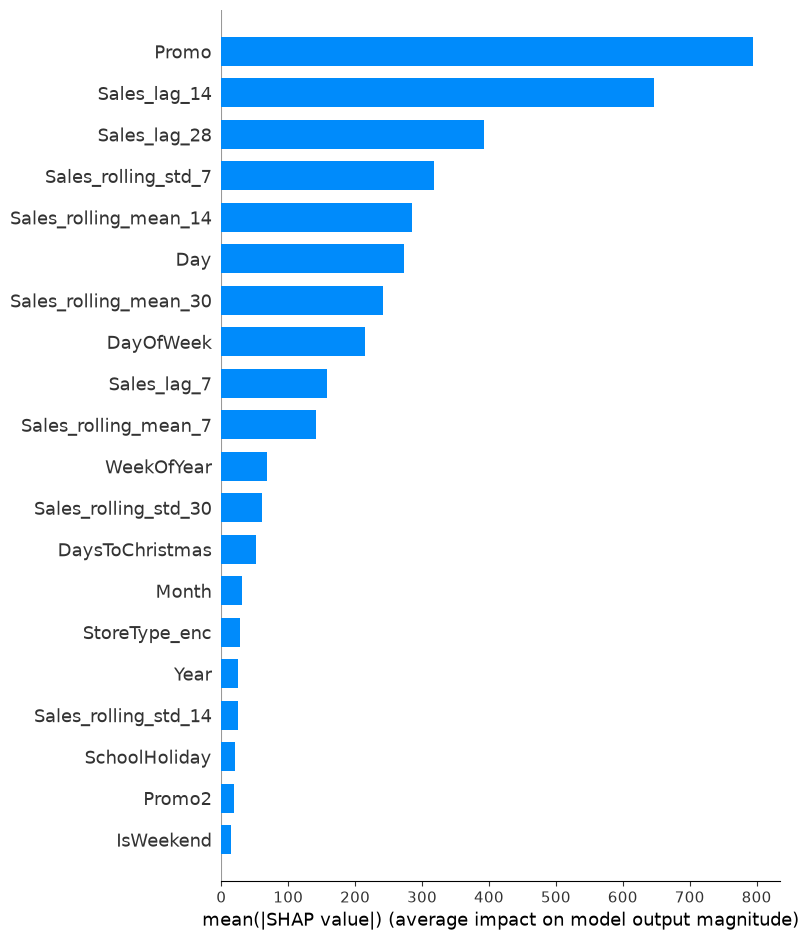

In [44]:
import shap

explainer = shap.TreeExplainer(model)

# Hız için test setinden 2000 satırlık bir örnek alıyoruz, SHAP tüm veri üzerinde çok yavaş çalışır
X_test_sample = X_test.sample(2000, random_state=42)
shap_values = explainer.shap_values(X_test_sample)

shap.summary_plot(shap_values, X_test_sample, plot_type='bar')

In [45]:
test_eval = test_eval.copy()
test_eval['XGB_Pred'] = preds
test_eval['Forecast_Error'] = test_eval['Sales'] - test_eval['XGB_Pred']

store_error_std = test_eval.groupby('Store')['Forecast_Error'].std()
store_error_std.describe()

count    1115.000000
mean      792.488878
std       456.497475
min       296.263881
25%       578.845606
50%       713.750399
75%       902.508802
max      9397.635388
Name: Forecast_Error, dtype: float64

In [46]:
store_error_std.sort_values(ascending=False).head(10)

Store
909     9397.635388
876     6738.473148
292     6002.333427
756     2622.507658
842     2589.935162
1027    2447.107714
279     2409.976456
251     2088.630885
1019    2025.689163
534     1970.276256
Name: Forecast_Error, dtype: float64

In [47]:
top_store = store_error_std.sort_values(ascending=False).index[0]
test_eval[test_eval['Store'] == top_store][['Date', 'Sales', 'XGB_Pred', 'Forecast_Error']]

,Date,Sales,XGB_Pred,Forecast_Error
828267,2015-06-19,11856,12830.686523,-974.686523
828268,2015-06-20,22882,9751.387695,13130.612305
828270,2015-06-22,41551,11063.469727,30487.530273
828271,2015-06-23,30038,11601.519531,18436.480469
828272,2015-06-24,18306,11313.781250,6992.218750
828273,2015-06-25,12241,10736.451172,1504.548828
828274,2015-06-26,9447,11685.971680,-2238.971680
828275,2015-06-27,6990,12464.587891,-5474.587891
828277,2015-06-29,6125,20642.193359,-14517.193359
828278,2015-06-30,10681,19131.371094,-8450.371094


In [48]:
df[(df['Store'] == top_store) & (df['Date'] >= '2015-06-15') & (df['Date'] <= '2015-07-05')][
    ['Date', 'Sales', 'Promo', 'SchoolHoliday', 'StateHoliday', 'CompetitionOpen']
]

,Date,Sales,Promo,SchoolHoliday,StateHoliday,CompetitionOpen
828263,2015-06-15,16602,1,0,0,0
828264,2015-06-16,14222,1,0,0,0
828265,2015-06-17,12244,1,0,0,0
828266,2015-06-18,10528,1,0,0,0
828267,2015-06-19,11856,1,0,0,0
828268,2015-06-20,22882,0,0,0,0
828269,2015-06-21,0,0,0,0,0
828270,2015-06-22,41551,0,0,0,0
828271,2015-06-23,30038,0,0,0,0
828272,2015-06-24,18306,0,0,0,0


In [49]:
def mad_based_std(series):
    median = series.median()
    mad = (series - median).abs().median()
    return mad * 1.4826  # normal dağılıma denk gelmesi için standart düzeltme katsayısı

store_error_robust_std = test_eval.groupby('Store')['Forecast_Error'].apply(mad_based_std)
store_error_robust_std.describe()

count    1115.000000
mean      703.525057
std       288.302051
min       228.040784
25%       512.053699
50%       651.521620
75%       828.702817
max      3734.725866
Name: Forecast_Error, dtype: float64

In [50]:
LEAD_TIME_DAYS = 5
Z_SCORE = 1.65  # %95 servis seviyesi

# Her mağaza için ortalama günlük tahmin edilen satış
store_avg_demand = test_eval.groupby('Store')['XGB_Pred'].mean()

# Güvenlik stoğu formülü
safety_stock = Z_SCORE * store_error_robust_std * np.sqrt(LEAD_TIME_DAYS)

# Reorder point: tedarik süresi boyunca beklenen talep + güvenlik stoğu
reorder_point = (store_avg_demand * LEAD_TIME_DAYS) + safety_stock

stock_plan = pd.DataFrame({
    'AvgDailyDemand': store_avg_demand,
    'ForecastErrorStd': store_error_robust_std,
    'SafetyStock': safety_stock,
    'ReorderPoint': reorder_point
})

stock_plan.describe()

,AvgDailyDemand,ForecastErrorStd,SafetyStock,ReorderPoint
count,1115.000000,1115.000000,1115.000000,1115.000000
mean,7045.372070,703.525057,2595.664255,37822.525012
std,2406.135986,288.302051,1063.693922,12787.649562
min,2547.376709,228.040784,841.359245,13770.679748
25%,5445.010498,512.053699,1889.228350,29272.685199
50%,6695.421875,651.521620,2403.796943,35808.887549
75%,8145.747803,828.702817,3057.509124,43857.412911
max,21610.849609,3734.725866,13779.316508,114490.076678


In [51]:
test_eval['Naive_Error'] = test_eval['Sales'] - test_eval['Sales_lag_7']
naive_error_robust_std = test_eval.groupby('Store')['Naive_Error'].apply(mad_based_std)
naive_avg_demand = test_eval.groupby('Store')['Sales_lag_7'].mean()

naive_safety_stock = Z_SCORE * naive_error_robust_std * np.sqrt(LEAD_TIME_DAYS)
naive_reorder_point = (naive_avg_demand * LEAD_TIME_DAYS) + naive_safety_stock

print(naive_reorder_point.describe())

count      1115.000000
mean      45604.563002
std       15483.556846
min       16684.085156
25%       35154.609500
50%       43381.093585
75%       52750.352776
max      134548.381786
dtype: float64


In [52]:
HOLDING_COST_RATE = 0.003     # fazla stoğun %0.3'ü kadar maliyet (5 günlük çevrim için)
STOCKOUT_MARGIN_RATE = 0.30   # karşılanamayan talebin %30'u kadar kar kaybı

def simulate_cost(reorder_points):
    total_cost = 0
    for store in test_eval['Store'].unique():
        store_data = test_eval[test_eval['Store'] == store].sort_values('Date')
        actual = store_data['Sales'].values
        rp = reorder_points.get(store, np.nan)
        if np.isnan(rp):
            continue
        n = len(actual)
        for i in range(0, n - LEAD_TIME_DAYS + 1, LEAD_TIME_DAYS):
            window_demand = actual[i:i + LEAD_TIME_DAYS].sum()
            if window_demand > rp:
                total_cost += (window_demand - rp) * STOCKOUT_MARGIN_RATE
            else:
                total_cost += (rp - window_demand) * HOLDING_COST_RATE
    return total_cost

cost_naive = simulate_cost(naive_reorder_point.to_dict())
cost_model = simulate_cost(reorder_point.to_dict())

improvement = (cost_naive - cost_model) / cost_naive * 100

print('Naive yaklaşım toplam maliyet:', round(cost_naive, 2))
print('Model tabanlı yaklaşım toplam maliyet:', round(cost_model, 2))
print('İyileşme:', round(improvement, 2), '%')

Naive yaklaşım toplam maliyet: 311469.59
Model tabanlı yaklaşım toplam maliyet: 1893297.26
İyileşme: -507.86 %


In [53]:
print('Ortalama tahmin hatası (yön dahil):', test_eval['Forecast_Error'].mean())
print()
print('Model bazlı ortalama günlük talep:', store_avg_demand.mean())
print('Naive bazlı ortalama günlük talep:', naive_avg_demand.mean())

Ortalama tahmin hatası (yön dahil): -56.875127083345916

Model bazlı ortalama günlük talep: 7045.372
Naive bazlı ortalama günlük talep: 6934.189274884335


In [54]:
# Mağaza bazında maliyet katkısını ayrıştıralım
def simulate_cost_by_store(reorder_points):
    results = {}
    for store in test_eval['Store'].unique():
        store_data = test_eval[test_eval['Store'] == store].sort_values('Date')
        actual = store_data['Sales'].values
        rp = reorder_points.get(store, np.nan)
        if np.isnan(rp):
            continue
        cost = 0
        n = len(actual)
        for i in range(0, n - LEAD_TIME_DAYS + 1, LEAD_TIME_DAYS):
            window_demand = actual[i:i + LEAD_TIME_DAYS].sum()
            if window_demand > rp:
                cost += (window_demand - rp) * STOCKOUT_MARGIN_RATE
            else:
                cost += (rp - window_demand) * HOLDING_COST_RATE
        results[store] = cost
    return pd.Series(results)

model_cost_by_store = simulate_cost_by_store(reorder_point.to_dict())
model_cost_by_store.sort_values(ascending=False).head(10)

909     14995.259384
335     10527.487448
876     10302.943072
453      8126.423107
310      7134.658853
544      7100.540896
732      6896.536399
1114     6771.061677
1027     6665.727422
261      6462.166169
dtype: float64

In [55]:
print('Model ForecastErrorStd (robust):')
print(store_error_robust_std.describe())
print()
print('Naive Error Std (robust):')
print(naive_error_robust_std.describe())
print()
print('Model ReorderPoint:')
print(reorder_point.describe())
print()
print('Naive ReorderPoint:')
print(naive_reorder_point.describe())

Model ForecastErrorStd (robust):
count    1115.000000
mean      703.525057
std       288.302051
min       228.040784
25%       512.053699
50%       651.521620
75%       828.702817
max      3734.725866
Name: Forecast_Error, dtype: float64

Naive Error Std (robust):
count     1115.000000
mean      2963.431517
std       1228.564775
min        397.336800
25%       2160.889500
50%       2824.353000
75%       3518.209800
max      18787.507200
Name: Naive_Error, dtype: float64

Model ReorderPoint:
count      1115.000000
mean      37822.525012
std       12787.649562
min       13770.679748
25%       29272.685199
50%       35808.887549
75%       43857.412911
max      114490.076678
dtype: float64

Naive ReorderPoint:
count      1115.000000
mean      45604.563002
std       15483.556846
min       16684.085156
25%       35154.609500
50%       43381.093585
75%       52750.352776
max      134548.381786
dtype: float64


In [56]:
def compute_window_errors(pred_col, lead_time=LEAD_TIME_DAYS):
    window_errors = {}
    window_demand_avg = {}
    for store in test_eval['Store'].unique():
        store_data = test_eval[test_eval['Store'] == store].sort_values('Date')
        actual = store_data['Sales'].values
        pred = store_data[pred_col].values
        errors, demands = [], []
        n = len(actual)
        for i in range(0, n - lead_time + 1, lead_time):
            window_actual = actual[i:i+lead_time].sum()
            window_pred = pred[i:i+lead_time].sum()
            errors.append(window_actual - window_pred)
            demands.append(window_pred)
        window_errors[store] = errors
        window_demand_avg[store] = np.mean(demands) if demands else np.nan
    return window_errors, window_demand_avg

model_window_errors, model_window_demand = compute_window_errors('XGB_Pred')
naive_window_errors, naive_window_demand = compute_window_errors('Sales_lag_7')

def empirical_safety_stock(window_errors, percentile=95):
    result = {}
    for store, errs in window_errors.items():
        errs = np.array(errs)
        # Sadece "az tahmin ettik" (stoksuzluk riski) tarafını hesaba katıyoruz
        result[store] = max(0, np.percentile(errs, percentile))
    return pd.Series(result)

model_safety_stock_emp = empirical_safety_stock(model_window_errors)
naive_safety_stock_emp = empirical_safety_stock(naive_window_errors)

model_reorder_point_emp = pd.Series(model_window_demand) + model_safety_stock_emp
naive_reorder_point_emp = pd.Series(naive_window_demand) + naive_safety_stock_emp

print('Model güvenlik stoğu (ampirik, %95):', model_safety_stock_emp.describe())
print()
print('Naive güvenlik stoğu (ampirik, %95):', naive_safety_stock_emp.describe())

Model güvenlik stoğu (ampirik, %95): count     1115.000000
mean      2482.225738
std       2512.227972
min          0.000000
25%       1349.062207
50%       2160.146094
75%       3016.412598
max      60520.627734
dtype: float64

Naive güvenlik stoğu (ampirik, %95): count     1115.000000
mean      9462.193587
std       4250.343634
min       1415.300000
25%       6831.650000
50%       8892.400000
75%      11249.700000
max      62249.600000
dtype: float64


In [57]:
def simulate_cost_empirical(pred_col, reorder_points):
    total_cost = 0
    for store in test_eval['Store'].unique():
        store_data = test_eval[test_eval['Store'] == store].sort_values('Date')
        actual = store_data['Sales'].values
        rp = reorder_points.get(store, np.nan)
        if np.isnan(rp):
            continue
        n = len(actual)
        for i in range(0, n - LEAD_TIME_DAYS + 1, LEAD_TIME_DAYS):
            window_demand = actual[i:i + LEAD_TIME_DAYS].sum()
            if window_demand > rp:
                total_cost += (window_demand - rp) * STOCKOUT_MARGIN_RATE
            else:
                total_cost += (rp - window_demand) * HOLDING_COST_RATE
    return total_cost

cost_naive_emp = simulate_cost_empirical('Sales_lag_7', naive_reorder_point_emp.to_dict())
cost_model_emp = simulate_cost_empirical('XGB_Pred', model_reorder_point_emp.to_dict())

improvement_emp = (cost_naive_emp - cost_model_emp) / cost_naive_emp * 100

print('Naive yaklaşım toplam maliyet (ampirik):', round(cost_naive_emp, 2))
print('Model tabanlı yaklaşım toplam maliyet (ampirik):', round(cost_model_emp, 2))
print('İyileşme:', round(improvement_emp, 2), '%')

Naive yaklaşım toplam maliyet (ampirik): 240958.87
Model tabanlı yaklaşım toplam maliyet (ampirik): 2358626.64
İyileşme: -878.85 %


In [58]:
# Newsvendor kritik oran formülü ile optimal servis seviyesi
critical_ratio = STOCKOUT_MARGIN_RATE / (STOCKOUT_MARGIN_RATE + HOLDING_COST_RATE)
print('Kritik oran (optimal servis seviyesi):', round(critical_ratio, 4))

from scipy.stats import norm
Z_OPTIMAL = norm.ppf(critical_ratio)
print('Buna karşılık gelen z-skoru:', round(Z_OPTIMAL, 3))

# Günlük bazlı, robust (MAD) sapma ile yeniden hesapla (8 pencere yerine ~30-40 günlük örneklem, daha stabil)
safety_stock_v2 = Z_OPTIMAL * store_error_robust_std * np.sqrt(LEAD_TIME_DAYS)
reorder_point_v2 = (store_avg_demand * LEAD_TIME_DAYS) + safety_stock_v2

naive_safety_stock_v2 = Z_OPTIMAL * naive_error_robust_std * np.sqrt(LEAD_TIME_DAYS)
naive_reorder_point_v2 = (naive_avg_demand * LEAD_TIME_DAYS) + naive_safety_stock_v2

cost_naive_v2 = simulate_cost(naive_reorder_point_v2.to_dict())
cost_model_v2 = simulate_cost(reorder_point_v2.to_dict())
improvement_v2 = (cost_naive_v2 - cost_model_v2) / cost_naive_v2 * 100

print('Naive maliyet (v2):', round(cost_naive_v2, 2))
print('Model maliyet (v2):', round(cost_model_v2, 2))
print('İyileşme (v2):', round(improvement_v2, 2), '%')

Kritik oran (optimal servis seviyesi): 0.9901
Buna karşılık gelen z-skoru: 2.33
Naive maliyet (v2): 380214.38
Model maliyet (v2): 1308787.48
İyileşme (v2): -244.22 %


In [59]:
optimal_percentile = critical_ratio * 100
print('Kullanılacak persentil:', round(optimal_percentile, 2))

model_safety_stock_v3 = empirical_safety_stock(model_window_errors, percentile=optimal_percentile)
naive_safety_stock_v3 = empirical_safety_stock(naive_window_errors, percentile=optimal_percentile)

model_reorder_point_v3 = pd.Series(model_window_demand) + model_safety_stock_v3
naive_reorder_point_v3 = pd.Series(naive_window_demand) + naive_safety_stock_v3

cost_naive_v3 = simulate_cost_empirical('Sales_lag_7', naive_reorder_point_v3.to_dict())
cost_model_v3 = simulate_cost_empirical('XGB_Pred', model_reorder_point_v3.to_dict())
improvement_v3 = (cost_naive_v3 - cost_model_v3) / cost_naive_v3 * 100

print('Naive maliyet (v3):', round(cost_naive_v3, 2))
print('Model maliyet (v3):', round(cost_model_v3, 2))
print('İyileşme (v3):', round(improvement_v3, 2), '%')

Kullanılacak persentil: 99.01
Naive maliyet (v3): 250673.27
Model maliyet (v3): 2170933.73
İyileşme (v3): -766.04 %


In [60]:
def simulate_cost_breakdown(pred_col, reorder_points):
    stockout_cost, holding_cost, stockout_events, holding_events = 0, 0, 0, 0
    for store in test_eval['Store'].unique():
        store_data = test_eval[test_eval['Store'] == store].sort_values('Date')
        actual = store_data['Sales'].values
        rp = reorder_points.get(store, np.nan)
        if np.isnan(rp):
            continue
        n = len(actual)
        for i in range(0, n - LEAD_TIME_DAYS + 1, LEAD_TIME_DAYS):
            window_demand = actual[i:i + LEAD_TIME_DAYS].sum()
            if window_demand > rp:
                stockout_cost += (window_demand - rp) * STOCKOUT_MARGIN_RATE
                stockout_events += 1
            else:
                holding_cost += (rp - window_demand) * HOLDING_COST_RATE
                holding_events += 1
    return stockout_cost, holding_cost, stockout_events, holding_events

for label, pred_col, rps in [('Model', 'XGB_Pred', model_reorder_point_v3.to_dict()),
                              ('Naive', 'Sales_lag_7', naive_reorder_point_v3.to_dict())]:
    sc, hc, se, he = simulate_cost_breakdown(pred_col, rps)
    print(f'{label} -> Stoksuzluk maliyeti: {round(sc,2)} ({se} olay), Elde tutma maliyeti: {round(hc,2)} ({he} olay)')

Model -> Stoksuzluk maliyeti: 2079894.79 (2513 olay), Elde tutma maliyeti: 91038.94 (5313 olay)
Naive -> Stoksuzluk maliyeti: 2590.01 (16 olay), Elde tutma maliyeti: 248083.26 (7810 olay)


In [61]:
def compute_relative_errors(pred_col):
    relative_errors = []
    for store in test_eval['Store'].unique():
        store_data = test_eval[test_eval['Store'] == store].sort_values('Date')
        actual = store_data['Sales'].values
        pred = store_data[pred_col].values
        n = len(actual)
        for i in range(0, n - LEAD_TIME_DAYS + 1, LEAD_TIME_DAYS):
            window_actual = actual[i:i+LEAD_TIME_DAYS].sum()
            window_pred = pred[i:i+LEAD_TIME_DAYS].sum()
            if window_pred > 0:
                relative_errors.append((window_actual - window_pred) / window_pred)
    return np.array(relative_errors)

model_rel_errors = compute_relative_errors('XGB_Pred')
naive_rel_errors = compute_relative_errors('Sales_lag_7')

print('Model havuzlanmış örneklem büyüklüğü:', len(model_rel_errors))
print('Naive havuzlanmış örneklem büyüklüğü:', len(naive_rel_errors))

model_pooled_margin = max(0, np.percentile(model_rel_errors, optimal_percentile))
naive_pooled_margin = max(0, np.percentile(naive_rel_errors, optimal_percentile))

print('Model havuzlanmış güvenlik marjı (oran):', round(model_pooled_margin, 4))
print('Naive havuzlanmış güvenlik marjı (oran):', round(naive_pooled_margin, 4))

Model havuzlanmış örneklem büyüklüğü: 7826
Naive havuzlanmış örneklem büyüklüğü: 7825
Model havuzlanmış güvenlik marjı (oran): 0.16
Naive havuzlanmış güvenlik marjı (oran): 0.5473


In [62]:
model_safety_stock_pooled = model_pooled_margin * store_avg_demand * LEAD_TIME_DAYS
naive_safety_stock_pooled = naive_pooled_margin * naive_avg_demand * LEAD_TIME_DAYS

model_reorder_point_pooled = (store_avg_demand * LEAD_TIME_DAYS) + model_safety_stock_pooled
naive_reorder_point_pooled = (naive_avg_demand * LEAD_TIME_DAYS) + naive_safety_stock_pooled

cost_naive_pooled = simulate_cost(naive_reorder_point_pooled.to_dict())
cost_model_pooled = simulate_cost(model_reorder_point_pooled.to_dict())
improvement_pooled = (cost_naive_pooled - cost_model_pooled) / cost_naive_pooled * 100

print('Naive maliyet (havuzlanmış):', round(cost_naive_pooled, 2))
print('Model maliyet (havuzlanmış):', round(cost_model_pooled, 2))
print('İyileşme (havuzlanmış):', round(improvement_pooled, 2), '%')

Naive maliyet (havuzlanmış): 461890.8
Model maliyet (havuzlanmış): 667662.3
İyileşme (havuzlanmış): -44.55 %


In [63]:
# Train içinde son 6 haftayı "kalibrasyon" dönemi olarak ayırıyoruz (test'e hiç dokunmuyoruz)
calib_split_date = pd.to_datetime(split_date) - pd.Timedelta(days=42)

calib_train = train_model_df[train_model_df['Date'] < calib_split_date]
calib_holdout = train_model_df[train_model_df['Date'] >= calib_split_date]

print('Kalibrasyon train:', calib_train.shape)
print('Kalibrasyon holdout:', calib_holdout.shape)

# Bu dilime özel bir model eğitiyoruz (asıl modelimize dokunmuyoruz)
calib_model = XGBRegressor(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=42
)
calib_model.fit(calib_train[feature_cols], calib_train['Sales'])

calib_holdout = calib_holdout.copy()
calib_holdout['Calib_Pred'] = calib_model.predict(calib_holdout[feature_cols])

Kalibrasyon train: (731560, 39)
Kalibrasyon holdout: (37372, 39)


In [64]:
def compute_relative_errors_from_df(data, pred_col, actual_col='Sales', lead_time=LEAD_TIME_DAYS):
    relative_errors = []
    for store in data['Store'].unique():
        store_data = data[data['Store'] == store].sort_values('Date')
        actual = store_data[actual_col].values
        pred = store_data[pred_col].values
        n = len(actual)
        for i in range(0, n - lead_time + 1, lead_time):
            window_actual = actual[i:i+lead_time].sum()
            window_pred = pred[i:i+lead_time].sum()
            if window_pred > 0:
                relative_errors.append((window_actual - window_pred) / window_pred)
    return np.array(relative_errors)

calib_rel_errors = compute_relative_errors_from_df(calib_holdout, 'Calib_Pred')
print('Kalibrasyon örneklem büyüklüğü:', len(calib_rel_errors))

calib_margin = max(0, np.percentile(calib_rel_errors, optimal_percentile))
print('Gerçek out-of-sample güvenlik marjı:', round(calib_margin, 4))

Kalibrasyon örneklem büyüklüğü: 6735
Gerçek out-of-sample güvenlik marjı: 0.1539


In [65]:
model_safety_stock_final = calib_margin * store_avg_demand * LEAD_TIME_DAYS
model_reorder_point_final = (store_avg_demand * LEAD_TIME_DAYS) + model_safety_stock_final

cost_model_final = simulate_cost(model_reorder_point_final.to_dict())
improvement_final = (cost_naive_pooled - cost_model_final) / cost_naive_pooled * 100

print('Naive maliyet (referans):', round(cost_naive_pooled, 2))
print('Model maliyet (gerçek out-of-sample kalibrasyon):', round(cost_model_final, 2))
print('İyileşme (final):', round(improvement_final, 2), '%')

Naive maliyet (referans): 461890.8
Model maliyet (gerçek out-of-sample kalibrasyon): 717561.09
İyileşme (final): -55.35 %
